In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, concatenate
from astropy.coordinates.erfa_astrom import erfa_astrom, ErfaAstromInterpolator
from astropy.time import Time

from ctapipe.io import TableLoader
from ctapipe.coordinates import TelescopeFrame
from ctapipe.core import QualityQuery
from ctapipe.io import HDF5MonitoringSource, TelescopeMonitoringType
from ctapipe.image.hillas import camera_to_shower_coordinates

In [2]:
erfa_astrom.set(ErfaAstromInterpolator(10 * u.min))

<ScienceState erfa_astrom: <astropy.coordinates.erfa_astrom.ErfaAstromInterpolator object at 0x7f59aca927b0>>

In [3]:
with TableLoader("build/on.dl1.h5") as loader:
    subarray = loader.subarray
    events = loader.read_telescope_events(pointing=True)
    obs = loader.read_observation_information()

In [20]:
obs["scheduled_start_time"].format = "isot"
obs[["obs_id", "scheduled_start_time"]]

obs_id,scheduled_start_time
int64,Time
5106,1996-05-07T03:35:57.795
5108,1996-05-07T04:19:24.590
5109,1996-05-07T04:48:03.780
5110,1996-05-07T05:16:49.200
5111,1996-05-07T05:45:24.380


In [5]:
len(events)

101775

In [6]:
# add pointing from individual runs..., maybe merging wasn't so convenient in the end

for col in ("altitude", "azimuth"):
    events[f"telescope_pointing_{col}"] = u.Quantity(np.zeros(len(events)), u.deg, copy=False)

for obs_id in obs["obs_id"]:
    source = HDF5MonitoringSource(input_files=[f"./build/on/gt{obs_id:06d}.pointing.mon.h5"], timestamp_tolerance="60 s")

    mask = events["obs_id"] == obs_id
    pointing = source.get_telescope_values(1, events[mask]["time"], TelescopeMonitoringType.TELESCOPE_POINTINGS)
    
    events["telescope_pointing_altitude"][mask] = pointing.alt.to(u.deg)
    events["telescope_pointing_azimuth"][mask] = pointing.az.to(u.deg)

events["pointing"] = SkyCoord(
    alt=events["telescope_pointing_altitude"].quantity,
    az=events["telescope_pointing_azimuth"].quantity,
    frame=AltAz(obstime=events["time"], location=subarray.reference_location)
)

[Text(0, 0.5, 'Pointing Altitude / deg')]

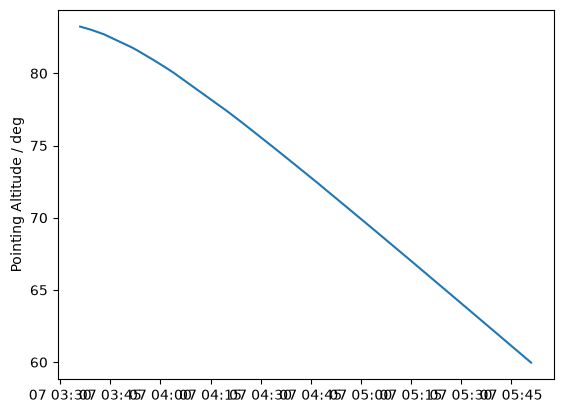

In [17]:
fig, ax = plt.subplots()

ax.plot(events["time"].to_datetime(), events["pointing"].alt.deg)

ax.set(ylabel='Pointing Altitude / deg')

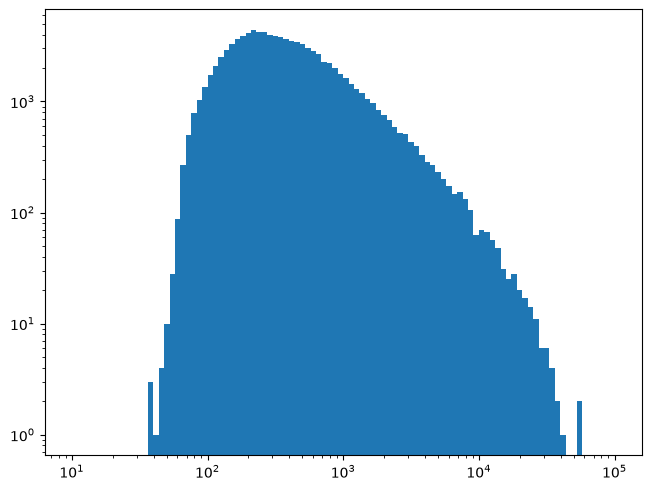

In [8]:
fig, ax = plt.subplots(1, 1, layout="constrained")


ax.hist(events["hillas_intensity"], bins=np.geomspace(10, 1e5, 101))
ax.set(xscale="log", yscale="log")

None

In [9]:
mrk421 = SkyCoord.from_name("Mrk 421")

In [10]:
mrk421_tel_frame = mrk421.transform_to(
    TelescopeFrame(
        telescope_pointing=events["pointing"],
        location=subarray.reference_location,
        obstime=events["time"],
    )
)

In [11]:
# should be close to 0, on obs
mrk421_tel_frame.fov_lon.mean(), mrk421_tel_frame.fov_lon.std()

(<Longitude -0.00187025 deg>, <Longitude 0.00798848 deg>)

In [12]:
# assume source in camera center, works for on/ off
long, trans = camera_to_shower_coordinates(
    0 * u.deg,
    0 * u.deg,
    events["hillas_fov_lon"].quantity,
    events["hillas_fov_lat"].quantity,
    events["hillas_psi"].quantity,
)

alpha = np.abs(np.arctan(trans / long).to(u.deg))
events["alpha"] = alpha

In [13]:
# some cuts, from Karl Kosack here: https://github.com/kosack/wuparam/blob/master/support/SuperCuts2001.conf
query = QualityQuery(
    quality_criteria=[
        ("width_low", "hillas_width >= 0.05"),
        ("width_high", "hillas_width <= 0.12"),
        ("length_low", "hillas_length >= 0.13"),
        ("length_high", "hillas_length <= 0.25"),
        ("distance_low", "hillas_r >= 0.4"),
        ("distance_high", "hillas_r <= 1.0"),
    ],
)

In [14]:
mask = query.get_table_mask(events)
selected = events[mask]

In [15]:
len(events), len(selected), len(selected) / len(events)

(101775, 3387, 0.033279292557111276)

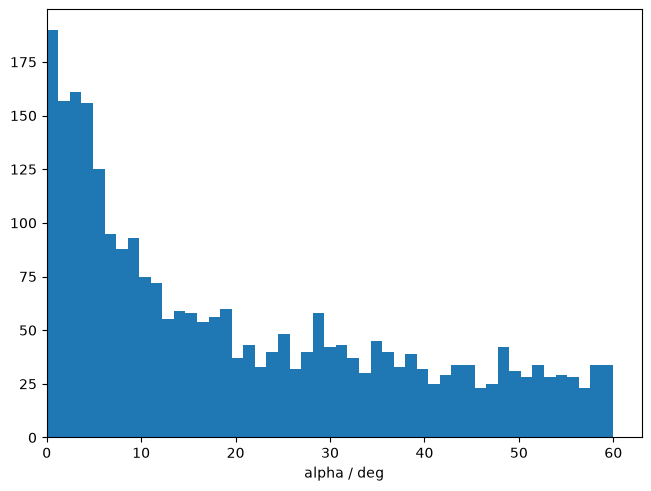

In [16]:
fig, ax = plt.subplots(1, 1, layout="constrained")

ax.hist(selected["alpha"].quantity.to_value(u.deg), bins=np.linspace(0, 60, 50))
ax.set(xlabel="alpha / deg", xlim=(0, None))

None